#imports and data preperation

In [ ]:
##might need to add the insurance dataset to the file system each time

from sklearn import preprocessing
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn import metrics
from sklearn.model_selection import KFold, cross_val_score
from sklearn.multioutput import MultiOutputRegressor
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error

from sklearn.svm import SVR
from sklearn import svm
from sklearn.neural_network import MLPRegressor

import matplotlib.pyplot as plt
import sklearn
import pandas as pd
import numpy as np
import copy
##loads the dataset in
df = pd.read_csv("traffic_accidents.csv")
df.columns

In [ ]:
##might need to add the insurance dataset to the file system each time

from sklearn import preprocessing
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn import metrics
from sklearn.model_selection import KFold, cross_val_score
from sklearn.multioutput import MultiOutputRegressor
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error

from sklearn.svm import SVR
from sklearn import svm
from sklearn.neural_network import MLPRegressor

import matplotlib.pyplot as plt
import sklearn
import pandas as pd
import numpy as np
import copy

## prints out some info about data set
#df.head()
#df.info()
##transforms the data and return the label encoder for inverseing transform later
def TransformLabelInDf(df, stringColName):
  label_encoder = preprocessing.LabelEncoder()
  label_encoder.fit(df[stringColName])
  df[stringColName] = label_encoder.transform(df[stringColName])
  return label_encoder
def InverseTransformLabelInDf(df, stringColName, encoder):
  df[stringColName] = df[stringColName].astype('int64')
  df[stringColName] = encoder.inverse_transform(df[stringColName])
  return


#sort out the data with a labelencoder so only float/numbers are used
columns_titles_for_num_units = ['crash_hour',
       'crash_day_of_week', 'crash_month', 'traffic_control_device', 'weather_condition',
       'lighting_condition', 'trafficway_type',
       'roadway_surface_cond', 'prim_contributory_cause',

       'num_units', 'injuries_total']

#pass num units predict ot injuries
columns_titles_for_injures = ['crash_hour',
       'crash_day_of_week', 'crash_month', 'traffic_control_device', 'weather_condition',
       'lighting_condition', 'first_crash_type', 'trafficway_type',
       'roadway_surface_cond', 'prim_contributory_cause',
       'num_units',
       'injuries_fatal',
       'injuries_incapacitating', 'injuries_non_incapacitating',
       'injuries_reported_not_evident', 'injuries_no_indication']

df1Eco = {}
df1 = df.copy();
df1 = df1[columns_titles_for_num_units]
for i in df1.columns:
  df1Eco[i] = TransformLabelInDf(df1, i)

# Create a new DataFrame with the column
df1Output = df[["num_units"]].copy()
# Remove the column from the original DataFrame
df1 = df1.drop(columns=["num_units"])

df2Eco = {}
df2 = df.copy();
df2 = df2[columns_titles_for_injures]
print()
for i in df2.columns:
  df2Eco[i] = TransformLabelInDf(df2, i)
df2.head()

# Create a new DataFrame with the column
# Select the columns to be copied to a new DataFrame
predListT = ['injuries_fatal', 'injuries_incapacitating', 'injuries_non_incapacitating',
             'injuries_reported_not_evident', 'injuries_no_indication']

# Copy those columns into a separate DataFrame
df2Output = df2[predListT].copy()

# Remove the columns from the original DataFrame
df2 = df2.drop(columns=predListT)

#allScores = {}

# a class wrapper that can create models and predicts values

In [ ]:
class ModelWrapper:
  def __init__(self):
    self.modelCreated = 0
    self.TheModel = 0

  def createTreeRegressor(self, trees = 155):
    self.TheModel = RandomForestRegressor(n_estimators=trees, random_state=0, oob_score=False)
    self.modelCreated = 1
  def createMLRegressor(self, maxIter = 70):
    self.TheModel = MLPRegressor(hidden_layer_sizes=100,max_iter=maxIter)# 1 hour 22 min 60 + 22 = 82
    self.modelCreated = 1
  def createSVRegressor(self, maxIter= 1600):
    Regressor = svm.LinearSVR(max_iter=maxIter)
    self.TheModel = RegressorMulitOut = MultiOutputRegressor(Regressor)
    self.modelCreated = 1

  ##cross validation Level One Out
  ##returns list of MSEscores
  def crossValLOO(self, inputData, outcomeData, n):
    if self.modelCreated == 0:
      print("need to create model")
      return
    segmentSize = inputData.shape[0]//n
    inputDataArray = []
    outcomeDataArray = []
    MSEscores = []
    MAEscores = []
    #get the segments and store them in array for easy access
    for i in range(0, n):
      start = segmentSize*i
      end = segmentSize*(i+1)
      if i == (n-1):
        end = inputData.shape[0]
      inputDataArray.append(inputData.iloc[segmentSize*i:segmentSize*(i+1),:])
      outcomeDataArray.append(outcomeData.iloc[segmentSize*i:segmentSize*(i+1),:])

    for i in range (0, n):
      #convcat dataframe for training
      trainData = pd.DataFrame();
      trainDataOutcome = pd.DataFrame();
      for x in range(0, n):
        if(x != i):
          trainData = pd.concat([trainData, inputDataArray[i]], axis=0)
          trainDataOutcome = pd.concat([trainDataOutcome, outcomeDataArray[i]], axis=0)

      print("fitting cycle = ", i)
      self.TheModel.fit(trainData, trainDataOutcome)
      predictions = self.TheModel.predict(inputDataArray[i])
      MSE = mean_squared_error(outcomeDataArray[i], predictions)
      MAE = mean_absolute_error(outcomeDataArray[i], predictions)
      MSEscores.append(MSE)
      MAEscores.append(MAE)
    return MSEscores, MAEscores

  ##returns mse score
  def FitAndMSE(self, inputData, outcomeData, percentForTrain):
    if self.modelCreated == 0:
      print("need to create model")
      return
    trainSize = int(inputData.shape[0]*percentForTrain);
    trainData = inputData.iloc[:trainSize,:]
    trainDataOutcome = outcomeData.iloc[:trainSize,:]

    testData  = inputData.iloc[trainSize:,:]
    testDataOutcome  = outcomeData.iloc[trainSize:,:]

    self.TheModel.fit(trainData, trainDataOutcome)
    predictions = self.TheModel.predict(testData)
    MSE = mean_squared_error(testDataOutcome, predictions)
    return MSE

  def predict(self, inputData):
    if self.modelCreated == 0:
      print("need to create model")
      return
    return self.TheModel.predict(inputData)

In [ ]:
from sklearn.preprocessing import LabelEncoder

# intial check of wrapper class to see if it can create and fit a model (spesifically a support vector regressor)

this section of code creates a support vector regressor and fit training data then predicts on the first part of the whole data, the output is inverse transofrmed so that the prediction is more easily readable

In [ ]:
test = ModelWrapper() #create a model wrapper class
test.createSVRegressor() #create a support vector regressor

print("test Input Data:\n", df1.iloc[0:1,:])#outputs waht data is will use for the prediction
scores = test.FitAndMSE(df1, df1Output, 0.75) #fits the trainsing data useing 75% as training data and also returns the mean square error
predict = pd.DataFrame(test.predict(df1.iloc[0:1,:]), columns=['num_units']) #predicts the values based on the input from above
print("MSE score:", scores)#prints mean square error
print(predict)
##convert the prediction to dataframe, convert data type round numbers(int)
##convert number to word for easier reading
predict = pd.DataFrame(predict, columns=["coverage_level", "charges"]) #converts to 2 collumn data frame as it will return an array with 2 elemnts
print("prediction:", predict)

#initial tests of all the the model types with cross validation (loo(leave one out))

cros validation useing leave one out


## tree regressor test

fitting cycle =  0
fitting cycle =  1
fitting cycle =  2
fitting cycle =  3


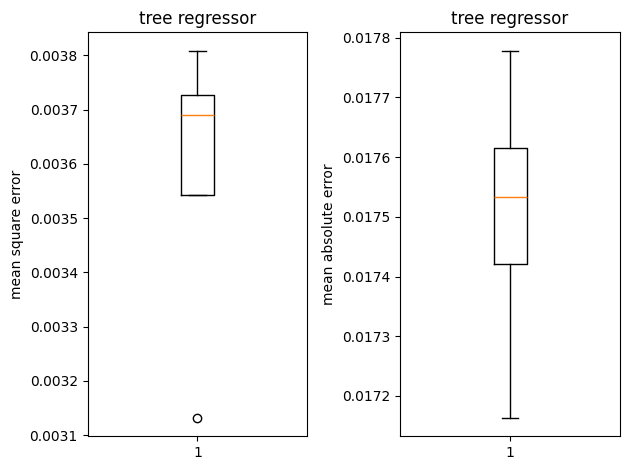

Cross Validation Scores-MSE:  [0.003699779100017815, 0.003131712504202005, 0.0036790742138193234, 0.0038085228473412613]
Cross Validation Scores-MAE:  [0.01756086386990701, 0.017163187057094752, 0.017507034422545826, 0.017778208503160496]


In [ ]:
##tre regressor good for guessing number of cars on road thouhg might be over fitting
#takes about 36 mins #finished
test = ModelWrapper()
test.createTreeRegressor() # 155 trees

MSEscores, MAEscores = test.crossValLOO(df2, df2Output, 4)

plt.subplot(1, 2, 1)
plt.boxplot(MSEscores)
plt.title('tree regressor')
plt.ylabel('mean square error')

plt.subplot(1, 2, 2)
plt.boxplot(MAEscores)
plt.title('tree regressor')
plt.ylabel('mean absolute error')
plt.tight_layout()

plt.show()
print("Cross Validation Scores-MSE: ", MSEscores)
print("Cross Validation Scores-MAE: ", MAEscores)

##ML regressor test

fitting cycle =  0


/usr/local/lib/python3.11/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (70) reached and the optimization hasn't converged yet.
  warnings.warn(


fitting cycle =  1


/usr/local/lib/python3.11/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (70) reached and the optimization hasn't converged yet.
  warnings.warn(


fitting cycle =  2


/usr/local/lib/python3.11/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (70) reached and the optimization hasn't converged yet.
  warnings.warn(


fitting cycle =  3


/usr/local/lib/python3.11/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (70) reached and the optimization hasn't converged yet.
  warnings.warn(


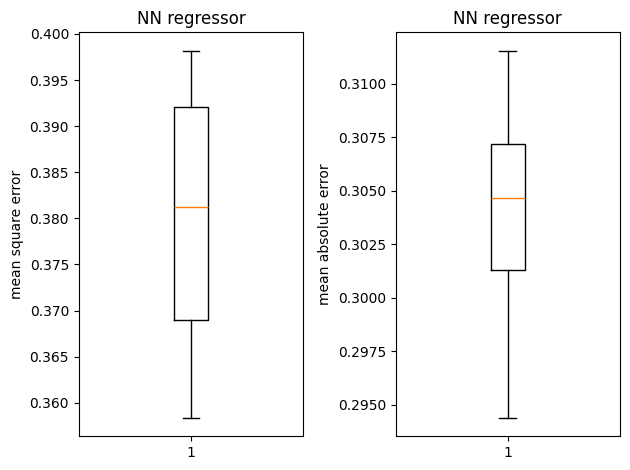

Cross Validation Scores-MSE:  [0.3583617824921709, 0.39002066507615096, 0.37247817867562144, 0.3981806176466115]
Cross Validation Scores-MAE:  [0.30360340296518906, 0.29439148334246723, 0.3057229004709338, 0.3115360008077633]


In [ ]:
##cross validation for neural network regression
##good for predicting potential injuries
#took 30 min
test = ModelWrapper()
test.createMLRegressor() # 70 iterations

MSEscores, MAEscores = test.crossValLOO(df2, df2Output, 4)

plt.subplot(1, 2, 1)
plt.boxplot(MSEscores)
plt.title('NN regressor')
plt.ylabel('mean square error')

plt.subplot(1, 2, 2)
plt.boxplot(MAEscores)
plt.title('NN regressor')
plt.ylabel('mean absolute error')
plt.tight_layout()

plt.show()
print("Cross Validation Scores-MSE: ", MSEscores)
print("Cross Validation Scores-MAE: ", MAEscores)

##support vector regressor test

fitting cycle =  0


/usr/local/lib/python3.11/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


fitting cycle =  1


/usr/local/lib/python3.11/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


fitting cycle =  2


/usr/local/lib/python3.11/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


fitting cycle =  3


/usr/local/lib/python3.11/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


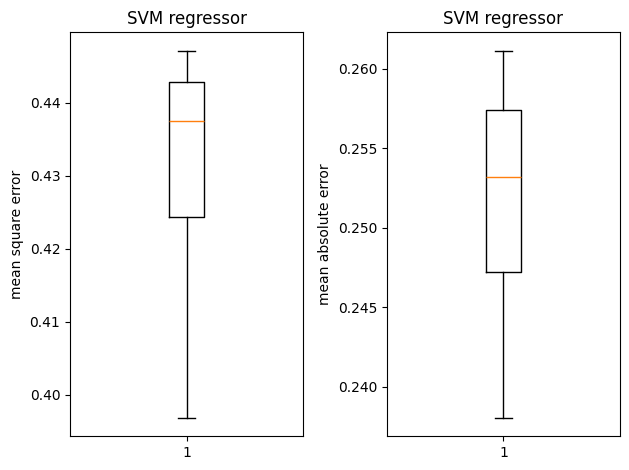

Cross Validation Scores-MSE:  [0.3968373407638689, 0.44146543821186235, 0.43346399686875137, 0.4470908757478643]
Cross Validation Scores-MAE:  [0.23803931376014692, 0.25614388862977017, 0.25023418660528607, 0.2611330851122015]


In [ ]:
##cross validation for SUPPORT VECTOR MACHINE regression #finished
#took 31 min
test = ModelWrapper()
test.createSVRegressor() # 1600 iterations

MSEscores, MAEscores = test.crossValLOO(df2, df2Output, 4)

plt.subplot(1, 2, 1)
plt.boxplot(MSEscores)
plt.title('SVM regressor')
plt.ylabel('mean square error')

plt.subplot(1, 2, 2)
plt.boxplot(MAEscores)
plt.title('SVM regressor')
plt.ylabel('mean absolute error')
plt.tight_layout()

plt.show()
print("Cross Validation Scores-MSE: ", MSEscores)
print("Cross Validation Scores-MAE: ", MAEscores)

#inital observations on the training outcomes

All three of the models where trained and tested for around 30mins each, useing the leave one out cross validation method which splits and systematilcaly designates training data and testing data. I used a split size of 4 when executing the cross validation, by doing this 3 groups will be used for training while the last group will be used for validating the effectivness of the models, calculating the mean square error and mean absolute error.

Out of all of the results the support vector machine and neural netwrok reggressors achived high scores in thier mean square error results, with the support vector machine getting the highest. The forest regressor got well under the nerual networks lowest score of 2,600,000 coming in at 8,600. Out of all three, for the time taken the forest regressor seems to be the best for fast training and quick results, potentially getting better with an increase of trees in the forest; but the current number of trees could also be at the optimal number where the mean square error and mean absolute error wont change drastically with more trees added. At that point it would potentially be better to start training and useing the neural network (or maybe the support vector if the training time improved or if i used a non linear support vector resgressor) instead as it could achive smaller error rates than the forest regressor given a longer training time.

#further testing of svm and ML would be better than trees by allowing for more time to traub

##testing of tree regressor

In [ ]:
#takes about ~60 mins #finished
test = ModelWrapper()
test.createTreeRegressor(310) # 310 trees

MSEscores, MAEscores = test.crossValLOO(theData, theOutcome, 4)

plt.subplot(1, 2, 1)
plt.boxplot(MSEscores)
plt.title('tree regressor')
plt.ylabel('mean square error')

plt.subplot(1, 2, 2)
plt.boxplot(MAEscores)
plt.title('tree regressor')
plt.ylabel('mean absolute error')
plt.tight_layout()

plt.show()
print("Cross Validation Scores-MSE: ", MSEscores)
print("Cross Validation Scores-MAE: ", MAEscores)

NameError: name 'theData' is not defined

##testing of ML regressor

In [ ]:
##cross validation for neural network regression
#took 66 mins
test = ModelWrapper()
test.createMLRegressor(160) # 160 iterations

MSEscores, MAEscores = test.crossValLOO(theData, theOutcome, 4)

plt.subplot(1, 2, 1)
plt.boxplot(MSEscores)
plt.title('NN regressor')
plt.ylabel('mean square error')

plt.subplot(1, 2, 2)
plt.boxplot(MAEscores)
plt.title('NN regressor')
plt.ylabel('mean absolute error')
plt.tight_layout()

plt.show()
print("Cross Validation Scores-MSE: ", MSEscores)
print("Cross Validation Scores-MAE: ", MAEscores)

##testing of support vector regressor

In [ ]:
##cross validation for SUPPORT VECTOR MACHINE regression #finished
#took 31 min
test = ModelWrapper()
test.createSVRegressor(3528) # 3528 iterations

MSEscores, MAEscores = test.crossValLOO(theData, theOutcome, 4)

plt.subplot(1, 2, 1)
plt.boxplot(MSEscores)
plt.title('SVM regressor')
plt.ylabel('mean square error')

plt.subplot(1, 2, 2)
plt.boxplot(MAEscores)
plt.title('SVM regressor')
plt.ylabel('mean absolute error')
plt.tight_layout()

plt.show()
print("Cross Validation Scores-MSE: ", MSEscores)
print("Cross Validation Scores-MAE: ", MAEscores)

#Conclusion

From further investigation, with an increased training time of around 60 minutes, the Forest reggressor is out performing the support vectors and NN regressor. To conclude, for this perticular problem a forest regressor would be the best model to use for predicting new coverage level and charges for health insurance based on previously stated data, as the MSE and MAE scores are low.